# PPG Segment Classification Training

This notebook trains a GRU-based binary classifier to distinguish between normal and alcohol conditions using PPG segment data from the 520S2 dataset.

In [64]:
import sys
sys.path.append('..')

import torch
from torch.utils.data import Dataset, DataLoader, TensorDataset
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap

from model import SpectraDermaPPGClassifier, SpectraDermaPPGDataset, train_model, evaluate_model, plot_training_history

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

mpl.rcParams['font.size'] = 10
mpl.rcParams['font.family'] = 'arial'

print("Libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")

Libraries imported successfully!
PyTorch version: 2.8.0+cu126
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070


## Load PPG Segment Data

Loading pre-segmented PPG data from normal and alcohol conditions. The segments are already preprocessed and saved as PyTorch tensors with shape (N, T, C) where:
- N = number of segments
- T = 256 (time steps)  
- C = 6 (channels)

In [2]:
# Load PPG segment data with enhanced features
normal_path = "../data/ppg_segments/520S2/normal.pt"
alcohol_path = "../data/ppg_segments/520S2/alcohol.pt"

print("Loading PPG segment data with enhanced features...")

try:
    # Load normal data (label = 0)
    normal_data = torch.load(normal_path)
    if not isinstance(normal_data, dict):
        raise ValueError("Data files must contain enhanced features (dict format)")
    
    print(f"Normal data loaded:")
    print(f"  Segments: {normal_data['segments'].shape}")
    print(f"  Metadata: {normal_data['metadata'].shape}")
    print(f"  DC values: {normal_data['dc_values'].shape}")
    
    # Load alcohol data (label = 1)  
    alcohol_data = torch.load(alcohol_path)
    if not isinstance(alcohol_data, dict):
        raise ValueError("Data files must contain enhanced features (dict format)")
    
    print(f"\nAlcohol data loaded:")
    print(f"  Segments: {alcohol_data['segments'].shape}")
    print(f"  Metadata: {alcohol_data['metadata'].shape}")
    print(f"  DC values: {alcohol_data['dc_values'].shape}")
    
    # Create labels
    n_normal = len(normal_data['segments'])
    n_alcohol = len(alcohol_data['segments'])
    normal_labels = [0] * n_normal  # Normal = 0
    alcohol_labels = [1] * n_alcohol  # Alcohol = 1
    
    print(f"\nDataset summary:")
    print(f"  Normal samples: {n_normal}")
    print(f"  Alcohol samples: {n_alcohol}")
    print(f"  Total samples: {n_normal + n_alcohol}")
    
except FileNotFoundError as e:
    print(f"Error: {e}")
    print("Please ensure the enhanced PPG segment files exist.")
except Exception as e:
    print(f"Error loading data: {e}")
    print("Data files must contain 'segments', 'metadata', and 'dc_values' keys.")

Loading PPG segment data with enhanced features...
Normal data loaded:
  Segments: torch.Size([1989, 256, 6])
  Metadata: torch.Size([1989, 3, 6])
  DC values: torch.Size([1989, 6])

Alcohol data loaded:
  Segments: torch.Size([2346, 256, 6])
  Metadata: torch.Size([2346, 3, 6])
  DC values: torch.Size([2346, 6])

Dataset summary:
  Normal samples: 1989
  Alcohol samples: 2346
  Total samples: 4335


## Data Preparation

Split the data into training, validation, and test sets, then create DataLoaders for efficient batch processing.

In [3]:
# Create datasets using PPGDataset class
print("Creating datasets with enhanced features...")

# Create datasets for normal and alcohol conditions
normal_dataset = SpectraDermaPPGDataset(normal_path, normal_labels)
alcohol_dataset = SpectraDermaPPGDataset(alcohol_path, alcohol_labels)

# Combine datasets
combined_dataset = torch.utils.data.ConcatDataset([normal_dataset, alcohol_dataset])

print(f"Combined dataset size: {len(combined_dataset)}")

# Split ratios
train_ratio = 0.8
val_ratio = 1 - train_ratio

# Calculate split sizes
total_size = len(combined_dataset)
train_size = int(round(train_ratio * total_size))
val_size = int(round(val_ratio * total_size))

print(f"\nDataset splits:")
print(f"  Training: {train_size} samples ({train_ratio*100:.1f}%)")
print(f"  Validation: {val_size} samples ({val_ratio*100:.1f}%)")

# Create random split
train_dataset, val_dataset = torch.utils.data.random_split(
    combined_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)  # For reproducibility
)

# Create data loaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print(f"\nDataLoaders created with batch size: {batch_size}")
print(f"  Training batches: {len(train_loader)}")
print(f"  Validation batches: {len(val_loader)}")

# Test a batch to verify data structure
sample_batch = next(iter(train_loader))
print(f"\nSample batch structure:")
print(f"  Segments shape: {sample_batch['segments'].shape}")
print(f"  Metadata shape: {sample_batch['metadata'].shape}")
print(f"  DC values shape: {sample_batch['dc_values'].shape}")
print(f"  Labels shape: {sample_batch['labels'].shape}")

Creating datasets with enhanced features...
Combined dataset size: 4335

Dataset splits:
  Training: 3468 samples (80.0%)
  Validation: 867 samples (20.0%)

DataLoaders created with batch size: 32
  Training batches: 109
  Validation batches: 28

Sample batch structure:
  Segments shape: torch.Size([32, 256, 6])
  Metadata shape: torch.Size([32, 3, 6])
  DC values shape: torch.Size([32, 256, 6])
  Labels shape: torch.Size([32])


## Model Initialization

Create and configure the GRU-based PPG classifier model.

In [11]:
# Model configuration
model_config = {
    'input_size': 6,      # 6 PPG channels
    'hidden_size': 64,    # GRU hidden dimension
    'num_layers': 2,      # Number of GRU layers
    'dropout': 0.5,       # Dropout rate
    'meta_hidden': 32,    # Hidden dimension for metadata processing
}

print("Initializing PPG Classifier...")
print(f"Model configuration: {model_config}")

# Initialize model
model = SpectraDermaPPGClassifier(**model_config)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\nModel Architecture:")
print(model)

print(f"\nModel Parameters:")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"\nTraining device: {device}")
model.to(device)

print("\n✓ Model initialized successfully!")


Initializing PPG Classifier...
Model configuration: {'input_size': 6, 'hidden_size': 64, 'num_layers': 2, 'dropout': 0.5, 'meta_hidden': 32}

Model Architecture:
SpectraDermaPPGClassifier(
  (gru): GRU(12, 64, num_layers=2, batch_first=True, dropout=0.5)
  (meta_fc): Sequential(
    (0): Linear(in_features=18, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (classifier): Sequential(
    (0): Linear(in_features=80, out_features=40, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=40, out_features=2, bias=True)
  )
)

Model Parameters:
  Total parameters: 44,394
  Trainable parameters: 44,394

Training device: cuda

✓ Model initialized successfully!


## Model Training

Train the model with the prepared data and monitor training progress.

In [ ]:
# Training configuration
training_config = {
    'num_epochs': 25,
    'learning_rate': 2e-5,
    'weight_decay': 1e-4,
    'device': device
}

print("Starting model training...")
print(f"Configuration: {training_config}")
print("=" * 50)

# Train the model
train_losses, val_accuracies, train_accuracies, val_losses = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    **training_config
)

print("=" * 50)
print("✓ Training completed!")
print(f"Final training loss: {train_losses[-1]:.4f}")
print(f"Final training accuracy: {train_accuracies[-1]:.4f}")
print(f"Final validation loss: {val_losses[-1]:.4f}")
print(f"Final validation accuracy: {val_accuracies[-1]:.4f}")
print(f"Best validation accuracy: {max(val_accuracies):.4f}")

Initializing PPG Classifier...
Model configuration: {'input_size': 6, 'hidden_size': 64, 'num_layers': 2, 'dropout': 0.5, 'meta_hidden': 32}

Model Architecture:
SpectraDermaPPGClassifier(
  (gru): GRU(12, 64, num_layers=2, batch_first=True, dropout=0.5)
  (meta_fc): Sequential(
    (0): Linear(in_features=18, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (classifier): Sequential(
    (0): Linear(in_features=80, out_features=40, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=40, out_features=2, bias=True)
  )
)

Model Parameters:
  Total parameters: 44,394
  Trainable parameters: 44,394

Training device: cuda

✓ Model initialized successfully!
Starting model training...
Configuration: {'num_epochs': 25, 'learning_rate': 2e-05, 'weight_decay': 0.0001, 'device': 'cuda'}


Training:   0%|          | 0/25 [00:00<?, ?epoch/s]

Epoch 1/25 - Train:   0%|          | 0/109 [00:00<?, ?batch/s]

Epoch 1/25 - Val:   0%|          | 0/28 [00:00<?, ?batch/s]

Epoch 2/25 - Train:   0%|          | 0/109 [00:00<?, ?batch/s]

...

Epoch 24/25 - Train:   0%|          | 0/109 [00:00<?, ?batch/s]

Epoch 24/25 - Val:   0%|          | 0/28 [00:00<?, ?batch/s]

Epoch 25/25 - Train:   0%|          | 0/109 [00:00<?, ?batch/s]

Epoch 25/25 - Val:   0%|          | 0/28 [00:00<?, ?batch/s]

✓ Training completed!
Final training loss: 0.0125
Final training accuracy: 1.0000
Final validation loss: 0.0023
Final validation accuracy: 1.0000
Best validation accuracy: 1.0000


## Training Visualization

Plot the training history to visualize model performance over epochs.

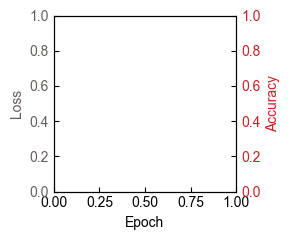

In [14]:
# Plot training history with twin y-axes
fig, ax1 = plt.subplots(figsize=(3, 2.5))

# Plot losses on left y-axis
color1 = '#655e5c'
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss', color=color1)
# ax1.plot(train_losses, color=color1, linestyle='-', label='Training Loss', linewidth=2)
# ax1.plot(val_losses, color=color1, linestyle='--', label='Validation Loss', linewidth=2)

# Create twin y-axis for accuracies
ax2 = ax1.twinx()
color2 = '#c92127'
ax2.set_ylabel('Accuracy', color=color2)
# ax2.plot(val_accuracies, color=color2, linestyle='--', label='Validation Accuracy', linewidth=2)
# ax2.plot(train_accuracies, color=color2, linestyle='-', label='Training Accuracy', linewidth=2)

ax1.tick_params(axis='x', direction='in')
ax1.tick_params(axis='y', labelcolor=color1, direction='in')
ax2.tick_params(axis='y', labelcolor=color2, direction='in')

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

pos_ax = ax1.get_position()

plt.tight_layout()
# plt.savefig('../figures/fig4/training_history.png', dpi=600, bbox_inches='tight', transparent=True)

ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right', frameon=False)
# plt.savefig('../figures/fig4/training_history.svg', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

## Save Trained Model

Save the trained model for future use and inference.

In [ ]:
# Save the trained model
model_save_path = "../models/model.pth"

# Create models directory if it doesn't exist
import os
os.makedirs(os.path.dirname(model_save_path), exist_ok=True)

# Save model state dict
torch.save(model.state_dict(), model_save_path)

# Save model configuration and metrics
model_info = {
    'model_config': model_config,
    'training_config': training_config,
    'train_losses': train_losses,
    'val_losses': val_losses,
    'train_accuracies': train_accuracies,
    'val_accuracies': val_accuracies,
    'model_type': 'ppg_classifier_enhanced'
}

info_save_path = "../models/model_info.pt"
torch.save(model_info, info_save_path)

print(f"✓ Model saved to: {model_save_path}")
print(f"✓ Model info saved to: {info_save_path}")

print(f"\n📋 To load the model later:")
print(f"model = PPGClassifier(**{model_config})")
print(f"model.load_state_dict(torch.load('{model_save_path}'))")
print(f"model.eval()")

✓ Model saved to: ../models/model.pth
✓ Model info saved to: ../models/model_info.pt

📋 To load the model later:


NameError: name 'model_config' is not defined

# Cross-Subject Evaluation

Test the trained model (trained on 520S2) on segments from other subjects to evaluate generalization performance.

In [93]:
# Load the trained model for cross-subject testing
print("Loading trained model for cross-subject evaluation...")

# Create a new model instance
test_model = SpectraDermaPPGClassifier(**model_config)
test_model.load_state_dict(torch.load(model_save_path))
test_model.to(device)
test_model.eval()

print("✓ Model loaded successfully!")

# Define available subjects and their data paths
subjects = {
    '555S2': {
        'normal': '../data/ppg_segments/555S2/normal.pt',
        'alcohol': '../data/ppg_segments/555S2/alcohol.pt'
    },
    '555S1': {
        'normal': '../data/ppg_segments/555S1/normal.pt',
        'alcohol': '../data/ppg_segments/555S1/alcohol.pt'
    },
    '563S2': {
        'normal': '../data/ppg_segments/563S2/normal.pt', 
        'alcohol': '../data/ppg_segments/563S2/alcohol.pt'
    }
}

print(f"\nAvailable subjects for testing: {list(subjects.keys())}")
print("Model trained on: 520S2")

print("Cross-Subject Evaluation Results:")
print("="*50)

# Test each subject
for subject_id, conditions in subjects.items():
    print(f"\nSubject: {subject_id}")
    
    for condition, file_path in conditions.items():
        # Load data
        data = torch.load(file_path)
        
        # Create dataset and loader
        label = 0 if 'normal' in condition or 'control' in condition else 1
        labels = [label] * len(data['segments'])
        dataset = SpectraDermaPPGDataset(file_path, labels)
        loader = DataLoader(dataset, batch_size=8, shuffle=False)
        
        # Evaluate
        accuracy, _, _ = evaluate_model(test_model, loader, device)
        print(f"  {condition}: {accuracy:.4f}")
            

print("\n" + "="*50)

Loading trained model for cross-subject evaluation...
✓ Model loaded successfully!

Available subjects for testing: ['555S2', '555S1', '563S2']
Model trained on: 520S2
Cross-Subject Evaluation Results:

Subject: 555S2
  normal: 0.8769
  alcohol: 0.9987

Subject: 555S1
  normal: 0.7880
  alcohol: 1.0000

Subject: 563S2
  normal: 0.9359
  alcohol: 0.4758



Generating Combined Confusion Matrix for All Cross-Subject Data

Processing Subject: 555S2
  normal: 2397 samples processed
  alcohol: 2346 samples processed
  Total samples from 555S2: 4743

Processing Subject: 555S1
  normal: 2142 samples processed
  alcohol: 2295 samples processed
  Total samples from 555S1: 4437

Processing Subject: 563S2
  normal: 1530 samples processed
  alcohol: 2295 samples processed
  Total samples from 563S2: 3825

COMBINED CROSS-SUBJECT RESULTS

Sample Distribution by Subject:
  555S2: 4743 samples
  555S1: 4437 samples
  563S2: 3825 samples

Combined Performance Metrics:
  Total Samples: 13005
  Accuracy: 0.8421
  Precision: 0.8712
  Recall: 0.8261
  F1-Score: 0.8481

Confusion Matrix Breakdown:
  True Negatives (Correct Normal): 5222
  False Positives (Normal → Alcohol): 847
  False Negatives (Alcohol → Normal): 1206
  True Positives (Correct Alcohol): 5730

Class-wise Performance:
  Normal Class Accuracy: 0.8604 (5222/6069)
  Alcohol Class Accuracy: 0.826

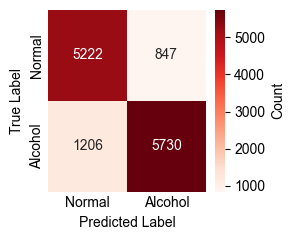

In [99]:
# Generate single combined confusion matrix for all test subjects
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("Generating Combined Confusion Matrix for All Cross-Subject Data")
print("="*60)

# Collect all predictions and true labels from all subjects
all_predictions = []
all_true_labels = []
subject_counts = {}

for subject_id, conditions in subjects.items():
    print(f"\nProcessing Subject: {subject_id}")
    
    subject_predictions = []
    subject_true_labels = []
    
    # Collect predictions for both conditions
    for condition, file_path in conditions.items():
        try:
            # Load data
            data = torch.load(file_path)
            
            # Create dataset and loader
            label = 0 if 'normal' in condition or 'control' in condition else 1
            labels = [label] * len(data['segments'])
            dataset = SpectraDermaPPGDataset(file_path, labels)
            loader = DataLoader(dataset, batch_size=8, shuffle=False)
            
            # Get predictions
            test_model.eval()
            condition_predictions = []
            condition_true = []
            
            with torch.no_grad():
                for batch in loader:
                    segments = batch['segments'].to(device)
                    metadata = batch['metadata'].to(device) 
                    dc_values = batch['dc_values'].to(device)
                    labels_batch = batch['labels'].to(device)
                    
                    outputs = test_model(segments, metadata, dc_values)
                    predicted = torch.argmax(outputs, dim=1)
                    
                    condition_predictions.extend(predicted.cpu().numpy())
                    condition_true.extend(labels_batch.cpu().numpy())
            
            subject_predictions.extend(condition_predictions)
            subject_true_labels.extend(condition_true)
            
            print(f"  {condition}: {len(condition_predictions)} samples processed")
            
        except Exception as e:
            print(f"  {condition}: ❌ Error - {e}")
    
    # Add this subject's data to the overall collection
    all_predictions.extend(subject_predictions)
    all_true_labels.extend(subject_true_labels)
    subject_counts[subject_id] = len(subject_predictions)
    
    print(f"  Total samples from {subject_id}: {len(subject_predictions)}")

if all_predictions and all_true_labels:
    print(f"\n{'='*60}")
    print("COMBINED CROSS-SUBJECT RESULTS")
    print(f"{'='*60}")
    
    # Calculate combined confusion matrix
    cm = confusion_matrix(all_true_labels, all_predictions)
    
    # Calculate metrics from combined matrix
    tn, fp, fn, tp = cm.ravel()
    accuracy = (tn + tp) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    # Create the visualization (KISS - minimal text)
    plt.figure(figsize=(3, 2.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
               xticklabels=['Normal', 'Alcohol'], 
               yticklabels=['Normal', 'Alcohol'],
               cbar_kws={'label': 'Count'})
    ax = plt.gca()
    ax.set_position(pos_ax)
    
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tick_params(length=0)
    
    # Print detailed summary
    print(f"\nSample Distribution by Subject:")
    for subject_id, count in subject_counts.items():
        print(f"  {subject_id}: {count} samples")
    
    print(f"\nCombined Performance Metrics:")
    print(f"  Total Samples: {len(all_predictions)}")
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall: {recall:.4f}")
    print(f"  F1-Score: {f1:.4f}")
    
    print(f"\nConfusion Matrix Breakdown:")
    print(f"  True Negatives (Correct Normal): {tn}")
    print(f"  False Positives (Normal → Alcohol): {fp}")
    print(f"  False Negatives (Alcohol → Normal): {fn}")
    print(f"  True Positives (Correct Alcohol): {tp}")
    
    # Calculate class-wise accuracy
    normal_accuracy = tn / (tn + fp) if (tn + fp) > 0 else 0
    alcohol_accuracy = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    print(f"\nClass-wise Performance:")
    print(f"  Normal Class Accuracy: {normal_accuracy:.4f} ({tn}/{tn + fp})")
    print(f"  Alcohol Class Accuracy: {alcohol_accuracy:.4f} ({tp}/{tp + fn})")

else:
    print("❌ No valid predictions collected from any subject.")

print(f"\n{'='*60}")

plt.tight_layout()
plt.savefig('../figures/fig4/confusion_matrix_combined.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

## Inter-Subject Consistency Analysis

Visualize how consistently the model performs across different test subjects.

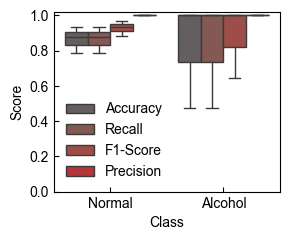

In [74]:
# Class-wise Consistency Box Plot with Multiple Metrics using Seaborn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns

class_metrics = {
    'Normal': {'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-Score': []},
    'Alcohol': {'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-Score': []}
}

for subject_id, conditions in subjects.items():
    for condition, file_path in conditions.items():
        # Load data
        data = torch.load(file_path)
        label = 0 if 'normal' in condition or 'control' in condition else 1
        labels = [label] * len(data['segments'])
        dataset = SpectraDermaPPGDataset(file_path, labels)
        loader = DataLoader(dataset, batch_size=8, shuffle=False)
        
        # Get predictions
        test_model.eval()
        preds = []
        true_labels = []
        
        with torch.no_grad():
            for batch in loader:
                segments = batch['segments'].to(device)
                metadata = batch['metadata'].to(device) 
                dc_values = batch['dc_values'].to(device)
                labels_batch = batch['labels'].to(device)
                
                outputs = test_model(segments, metadata, dc_values)
                predicted = torch.argmax(outputs, dim=1)
                
                preds.extend(predicted.cpu().numpy())
                true_labels.extend(labels_batch.cpu().numpy())
        
        # Calculate all metrics for this condition
        accuracy = accuracy_score(true_labels, preds)
        recall = recall_score(true_labels, preds, pos_label=label, zero_division=0)
        f1 = f1_score(true_labels, preds, pos_label=label, zero_division=0)
        precision = precision_score(true_labels, preds, pos_label=label, zero_division=0)
        
        class_name = 'Normal' if label == 0 else 'Alcohol'
        class_metrics[class_name]['Accuracy'].append(accuracy)
        class_metrics[class_name]['Recall'].append(recall)
        class_metrics[class_name]['F1-Score'].append(f1)
        class_metrics[class_name]['Precision'].append(precision)

# Prepare data for seaborn
data_for_plot = []
for class_name in ['Normal', 'Alcohol']:
    for metric in ['Accuracy', 'Recall', 'F1-Score', 'Precision']:
        for value in class_metrics[class_name][metric]:
            data_for_plot.append({
                'Class': class_name,
                'Metric': metric,
                'Score': value
            })

df_plot = pd.DataFrame(data_for_plot)

# Create the plot using seaborn with muted color scheme
plt.figure(figsize=(3, 2.5))

colors = ['#655e5d', '#8c534b', '#ac423a', '#c92128']

sns.boxplot(data=df_plot, x='Class', y='Score', hue='Metric', palette=colors)
plt.ylabel('Score')
plt.xlabel('Class')
plt.ylim(0, 1.02)
plt.legend(frameon=False)
plt.tick_params(direction='in')

ax = plt.gca()
ax.set_position(pos_ax)

plt.tight_layout()
plt.savefig('../figures/fig4/classwise_metrics_boxplot.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

## Visualize Sample PPG Segments from Different Subjects and Classes with Average Waveform Overlay

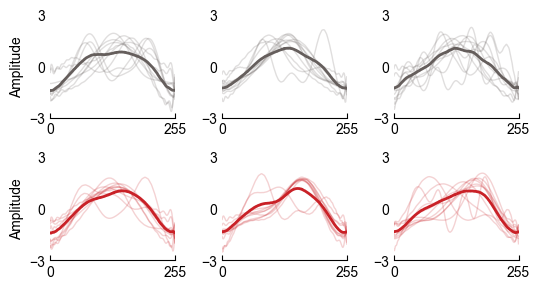

In [91]:
viz_subjects = ['555S2', '555S1', '563S2']
classes = ['normal', 'alcohol']
class_labels = ['Normal', 'Alcohol']

# Set up the 2x3 subplot
fig, axes = plt.subplots(2, 3, figsize=(5.5, 3))
fig.subplots_adjust(wspace=0.)

# Colors for different channels
class_colors = ['#655e5c', '#c92127']
alpha_overlay = 0.2

# Iterate through each subplot
for class_idx, class_name in enumerate(classes):
    for subj_idx, subject_id in enumerate(viz_subjects):
        ax = axes[class_idx, subj_idx]

        # Load data for this subject/class combination
        file_path = f'../data/ppg_segments/{subject_id}/{class_name}.pt'
        data = torch.load(file_path)
        segments = data['segments']  # Shape: (N, T, C)
        
        # Select first 10 samples (or all if less than 10)
        n_samples = min(10, len(segments))
        selected_segments = segments[:n_samples]
        
        # Plot each sample using only channel 2
        for sample_idx in range(n_samples):
            sample = selected_segments[sample_idx]  # Shape: (T, C)
            channel_idx = 2
            ax.plot(sample[:, channel_idx], 
                    color=class_colors[class_idx],
                    alpha=alpha_overlay,
                    linewidth=1)

        # Plot the average waveform of each subject each class, use the same color as the individual samples
        avg_waveform = torch.mean(segments, dim=0)  # Shape: (T, C)
        ax.plot(avg_waveform[:, channel_idx], color=class_colors[class_idx], linewidth=2, label='Average')

        ax.set_xlim(0, sample.shape[0]-1)
        ax.set_ylim(-3, 3)

        ax.set_xticks([0, sample.shape[0]-1])
        ax.set_yticks([-3, 0, 3])
        # ax.set_title(f'{subject_id}\n{class_labels[class_idx]}', fontsize=10)

        if subj_idx == 0:  # Only leftmost column gets y-label
            ax.set_ylabel('Amplitude')
        
        # Style the axes
        ax.tick_params(direction='in')
        ax.tick_params(axis='y', length=0)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.savefig('../figures/fig4/subject_class_samples_overlay.png', 
            dpi=600, bbox_inches='tight', transparent=True)
plt.show()

## t-SNE

In [55]:
from pathlib import Path

from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

base_dir = Path("../data/ppg_segments")
subjects = ["555S2", "555S1", "563S2"]
conditions = [("normal.pt", 0), ("alcohol.pt", 1)]  # (filename, label)

X_list, y_list, subj_list = [], [], []

def seg_to_simple_feats(seg_TxC):
    # Minimal, stable features: per-channel mean and std over time (2*C dims)
    seg = torch.as_tensor(seg_TxC).float()
    ch_mean = seg.mean(dim=0)          # (C,)
    ch_std  = seg.std(dim=0, unbiased=False)  # (C,)
    return torch.cat([ch_mean, ch_std], dim=0).numpy()

total_counts = []

for subj in subjects:
    subj_dir = base_dir / subj
    for fname, lab in conditions:
        fpath = subj_dir / fname
        if not fpath.exists():
            print(f"[warn] Missing file: {fpath}")
            continue

        data_dict = torch.load(fpath)
        N = len(data_dict["segments"])
        labels_vec = np.full(N, lab, dtype=np.int64)

        ds = SpectraDermaPPGDataset(fpath, labels=labels_vec)
        total_counts.append((subj, fname, len(ds)))

        for i in range(len(ds)):
            item = ds[i]
            seg = item["segments"]  # (T, C)
            feat = seg_to_simple_feats(seg)

            # Use a single DC snapshot per channel (avoid the broadcast repetition)
            dc = item.get("dc_values", None)
            if dc is not None:
                dc = np.asarray(dc)
                if dc.ndim == 2:          # (T, C) from broadcast
                    dc = dc[0]            # take first time step to avoid repeats
                dc = dc.reshape(-1)
                feat = np.concatenate([feat, dc])

            meta = item.get("metadata", None)
            if meta is not None:
                feat = np.concatenate([feat, np.asarray(meta).reshape(-1)])

            X_list.append(feat)
            y_list.append(int(item["labels"]))
            subj_list.append(subj)

# Show how many samples we actually used
print("Counts per (subject, condition):")
for s, f, n in total_counts:
    print(f"  {s} / {f}: {n}")
print(f"Total samples: {len(X_list)}")

Counts per (subject, condition):
  555S2 / normal.pt: 2397
  555S2 / alcohol.pt: 2346
  555S1 / normal.pt: 2142
  555S1 / alcohol.pt: 2295
  563S2 / normal.pt: 1530
  563S2 / alcohol.pt: 2295
Total samples: 13005


In [57]:
X = np.vstack(X_list)
y = np.asarray(y_list)
subj_arr = np.asarray(subj_list)

X_std = StandardScaler().fit_transform(X)

# Use a modest perplexity for a few hundred samples
tsne = TSNE(n_components=2, perplexity=20, random_state=42, init="pca", learning_rate="auto")
Z = tsne.fit_transform(X_std)

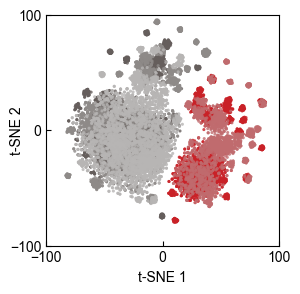

In [84]:
plt.figure(figsize=(3, 3))

n_subjects = len(np.unique(subj_arr))
alcohol_colors = Colormap(['#c92127', '#b7b5b4'])(np.linspace(0, 1, n_subjects))
normal_colors = Colormap(['#655e5c', '#b7b5b4'])(np.linspace(0, 1, n_subjects))

# Plot
subjects = np.unique(subj_arr)
marker = "o"  # same marker for all

for i, subj in enumerate(subjects):
    idx_subj = (subj_arr == subj)

    # Alcohol (label=1): use color from alcohol gradient
    idx_alc = idx_subj & (y == 1)
    if np.any(idx_alc):
        plt.scatter(
            Z[idx_alc, 0], Z[idx_alc, 1],
            s=5,
            marker=marker,
            c=[alcohol_colors[i]],
            edgecolors="none",
            linewidths=0,
            alpha=0.8
        )

    # Normal (label=0): use color from normal gradient
    idx_norm = idx_subj & (y == 0)
    if np.any(idx_norm):
        plt.scatter(
            Z[idx_norm, 0], Z[idx_norm, 1],
            s=5,
            marker=marker,
            c=[normal_colors[i]],
            edgecolors="none",
            linewidths=0,
            alpha=0.8
        )
            
plt.xlim(-100, 100)
plt.ylim(-100, 100)
plt.xticks([-100, 0, 100])
plt.yticks([-100, 0, 100])

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2", labelpad=-10)

plt.tick_params(direction='in')
plt.gca().set_position(pos_ax)

# plt.tight_layout()
plt.savefig('../figures/fig4/tsne_combined_features.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()